--- STARTING PARALLEL GENERATION ---


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:   34.0s
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:  6.0min
[Parallel(n_jobs=-1)]: Done 284 tasks      | elapsed: 10.7min
[Parallel(n_jobs=-1)]: Done 446 tasks      | elapsed: 16.7min
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed: 24.0min
[Parallel(n_jobs=-1)]: Done 878 tasks      | elapsed: 32.8min
[Parallel(n_jobs=-1)]: Done 1148 tasks      | elapsed: 42.7min
[Parallel(n_jobs=-1)]: Done 1454 tasks      | elapsed: 54.0min
[Parallel(n_jobs=-1)]: Done 1796 tasks      | elapsed: 66.7min
[Parallel(n_jobs=-1)]: Done 2000 out of 2000 | elapsed: 74.4min finished



Generation Complete in 4462.62 seconds.
Valid Samples: 2000/2000


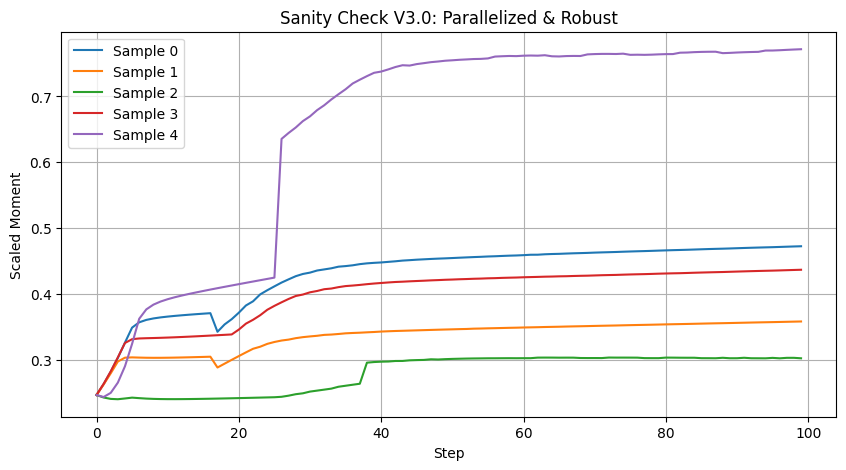

In [ ]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from scipy.optimize import brentq
from joblib import Parallel, delayed # <--- THE SPEED BOOST
import time

# ==========================================
# 1. ROBUST MATERIAL MODELS
# ==========================================
def material_steel(strain, fy, Es=200000):
    ey = fy / Es
    if abs(strain) <= ey:
        return strain * Es
    else:
        return np.sign(strain) * (fy + (abs(strain) - ey) * Es * 0.01)

def material_concrete(strain, fc, epsilon_c0=0.002, epsilon_cu=0.01):
    if strain > 0: return 0
    strain = abs(strain)
    if strain <= epsilon_c0:
        return fc * (2 * (strain/epsilon_c0) - (strain/epsilon_c0)**2)
    elif strain <= epsilon_cu:
        return fc * (1 - 0.15 * (strain - epsilon_c0) / (epsilon_cu - epsilon_c0))
    else:
        return 0

# ==========================================
# 2. ITERATIVE SECTION SOLVER
# ==========================================
def calculate_force_moment(na_depth, phi, D, t, fy, fc, n_layers=100): # n_layers optimized to 100 for speed
    R_outer = D / 2
    R_inner = R_outer - t
    dy = D / n_layers
    y_coords = np.linspace(-R_outer + dy/2, R_outer - dy/2, n_layers)

    net_force = 0
    net_moment = 0

    # Vectorized calculation inside the layer loop (Small speedup)
    # But keeping explicit loop for clarity as per user request
    for y in y_coords:
        strain = -phi * (y - na_depth)

        if abs(y) < R_outer: width_total = 2 * np.sqrt(R_outer**2 - y**2)
        else: width_total = 0
        if abs(y) < R_inner: width_inner = 2 * np.sqrt(R_inner**2 - y**2)
        else: width_inner = 0

        area_steel = (width_total - width_inner) * dy
        area_concrete = width_inner * dy

        sig_s = material_steel(strain, fy)
        sig_c = material_concrete(strain, fc)

        force_layer = (sig_s * area_steel) + (sig_c * area_concrete)
        net_force += force_layer
        net_moment += force_layer * y

    return net_force, -net_moment / 1e6

def get_moment_curvature_robust(D, t, fy, fc, n_points=100):
    # Dynamic Curvature Limit
    max_phi = (0.005 / (D/2)) * 8
    curvatures = np.linspace(0, max_phi, n_points)
    moments = []
    current_na = 0

    for phi in curvatures:
        if phi == 0:
            moments.append(0)
            continue

        def force_imbalance(na):
            F, _ = calculate_force_moment(na, phi, D, t, fy, fc)
            return F

        try:
            # FIX APPLIED: Widened bounds to 0.99 to prevent crashing on thin sections
            root_na = brentq(force_imbalance, -D/2 * 0.99, D/2 * 0.99)
            current_na = root_na
        except:
            root_na = current_na

        _, M = calculate_force_moment(root_na, phi, D, t, fy, fc)
        moments.append(M)

    return moments

# ==========================================
# 3. PARALLEL GENERATION WRAPPER
# ==========================================
def generate_one_sample(i, param_bounds):
    # This function generates ONE sample.
    # Joblib will run this function on multiple cores at once.

    # Random Generation inside the worker
    np.random.seed(i) # Ensure reproducibility per core
    D = np.random.uniform(*param_bounds['D'])
    t = np.random.uniform(*param_bounds['t'])
    fy = np.random.uniform(*param_bounds['fy'])
    fc = np.random.uniform(*param_bounds['fc'])

    try:
        M_curve = get_moment_curvature_robust(D, t, fy, fc, n_points=100)

        # Sanity Check
        if np.max(M_curve) < 1 or np.isnan(M_curve).any():
            return None

        return ([D, t, fy, fc], M_curve)
    except:
        return None

# ==========================================
# 4. EXECUTION
# ==========================================
print(f"--- STARTING PARALLEL GENERATION ---")
start_time = time.time()

N_SAMPLES = 2000
param_bounds = {'D': (200, 800), 't': (4, 20), 'fy': (235, 460), 'fc': (30, 80)}

# THE IMPORTANT LINE: n_jobs=-1 uses ALL available CPU cores
results = Parallel(n_jobs=-1, verbose=5)(
    delayed(generate_one_sample)(i, param_bounds) for i in range(N_SAMPLES)
)

# Filter out None (failed samples)
valid_results = [r for r in results if r is not None]
X_raw = [r[0] for r in valid_results]
y_raw = [r[1] for r in valid_results]

print(f"\nGeneration Complete in {time.time() - start_time:.2f} seconds.")
print(f"Valid Samples: {len(X_raw)}/{N_SAMPLES}")

# Processing for AI
X_data = np.array(X_raw)
y_data = np.array(y_raw)

scaler_X = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X_data)

scaler_y = MinMaxScaler()
y_flat = y_data.reshape(-1, 1)
y_flat_scaled = scaler_y.fit_transform(y_flat)
y_scaled = y_flat_scaled.reshape(len(X_raw), 100)

# Final Sanity Plot
plt.figure(figsize=(10, 5))
for i in range(5):
    plt.plot(y_scaled[i], label=f"Sample {i}")
plt.title("Sanity Check V3.0: Parallelized & Robust")
plt.xlabel("Step")
plt.ylabel("Scaled Moment")
plt.legend()
plt.grid(True)
plt.show()

# Save split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

--- STARTING MULTI-TASK PHYSICS ENGINE ---


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:   49.2s
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:  2.8min
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:  6.1min
[Parallel(n_jobs=-1)]: Done 284 tasks      | elapsed: 10.7min
[Parallel(n_jobs=-1)]: Done 446 tasks      | elapsed: 16.7min
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed: 23.9min
[Parallel(n_jobs=-1)]: Done 878 tasks      | elapsed: 32.6min
[Parallel(n_jobs=-1)]: Done 1148 tasks      | elapsed: 42.4min
[Parallel(n_jobs=-1)]: Done 1454 tasks      | elapsed: 53.6min
[Parallel(n_jobs=-1)]: Done 1796 tasks      | elapsed: 66.2min
[Parallel(n_jobs=-1)]: Done 2000 out of 2000 | elapsed: 73.7min finished



Generation Complete in 4420.03 seconds.
Valid Samples: 2000/2000


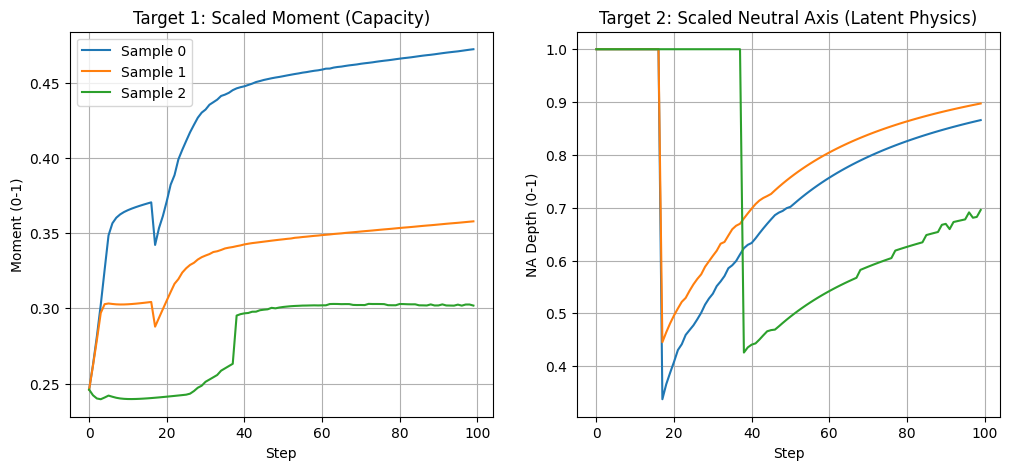

Dataset Shape: (1600, 100, 2)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from scipy.optimize import brentq
from joblib import Parallel, delayed
import time

# ==========================================
# 1. ROBUST MATERIAL MODELS
# ==========================================
def material_steel(strain, fy, Es=200000):
    ey = fy / Es
    if abs(strain) <= ey:
        return strain * Es
    else:
        return np.sign(strain) * (fy + (abs(strain) - ey) * Es * 0.01)

def material_concrete(strain, fc, epsilon_c0=0.002, epsilon_cu=0.01):
    if strain > 0: return 0
    strain = abs(strain)
    if strain <= epsilon_c0:
        return fc * (2 * (strain/epsilon_c0) - (strain/epsilon_c0)**2)
    elif strain <= epsilon_cu:
        return fc * (1 - 0.15 * (strain - epsilon_c0) / (epsilon_cu - epsilon_c0))
    else:
        return 0

# ==========================================
# 2. ITERATIVE SECTION SOLVER
# ==========================================
def calculate_force_moment(na_depth, phi, D, t, fy, fc, n_layers=100):
    R_outer = D / 2
    R_inner = R_outer - t
    dy = D / n_layers
    y_coords = np.linspace(-R_outer + dy/2, R_outer - dy/2, n_layers)

    net_force = 0
    net_moment = 0

    for y in y_coords:
        strain = -phi * (y - na_depth)

        if abs(y) < R_outer: width_total = 2 * np.sqrt(R_outer**2 - y**2)
        else: width_total = 0
        if abs(y) < R_inner: width_inner = 2 * np.sqrt(R_inner**2 - y**2)
        else: width_inner = 0

        area_steel = (width_total - width_inner) * dy
        area_concrete = width_inner * dy

        sig_s = material_steel(strain, fy)
        sig_c = material_concrete(strain, fc)

        force_layer = (sig_s * area_steel) + (sig_c * area_concrete)
        net_force += force_layer
        net_moment += force_layer * y

    return net_force, -net_moment / 1e6

def get_moment_curvature_robust(D, t, fy, fc, n_points=100):
    # Dynamic Curvature Limit
    max_phi = (0.005 / (D/2)) * 8
    curvatures = np.linspace(0, max_phi, n_points)

    moments = []
    neutral_axes = [] # <--- UPGRADE B: We now store the Latent Variable

    current_na = 0

    for phi in curvatures:
        if phi == 0:
            moments.append(0)
            neutral_axes.append(0)
            continue

        def force_imbalance(na):
            F, _ = calculate_force_moment(na, phi, D, t, fy, fc)
            return F

        try:
            root_na = brentq(force_imbalance, -D/2 * 0.99, D/2 * 0.99)
            current_na = root_na
        except:
            root_na = current_na

        _, M = calculate_force_moment(root_na, phi, D, t, fy, fc)

        moments.append(M)
        neutral_axes.append(root_na) # <--- Save the physics state

    return moments, neutral_axes

# ==========================================
# 3. PARALLEL GENERATION WRAPPER
# ==========================================
def generate_one_sample(i, param_bounds):
    np.random.seed(i)
    D = np.random.uniform(*param_bounds['D'])
    t = np.random.uniform(*param_bounds['t'])
    fy = np.random.uniform(*param_bounds['fy'])
    fc = np.random.uniform(*param_bounds['fc'])

    try:
        # UPGRADE B: Unpack both M and NA
        M_curve, NA_curve = get_moment_curvature_robust(D, t, fy, fc, n_points=100)

        if np.max(M_curve) < 1 or np.isnan(M_curve).any():
            return None

        # Return inputs + Moment + Neutral Axis
        return ([D, t, fy, fc], M_curve, NA_curve)
    except:
        return None

# ==========================================
# 4. EXECUTION
# ==========================================
print(f"--- STARTING MULTI-TASK PHYSICS ENGINE ---")
start_time = time.time()

N_SAMPLES = 2000
param_bounds = {'D': (200, 800), 't': (4, 20), 'fy': (235, 460), 'fc': (30, 80)}

results = Parallel(n_jobs=-1, verbose=5)(
    delayed(generate_one_sample)(i, param_bounds) for i in range(N_SAMPLES)
)

valid_results = [r for r in results if r is not None]
X_raw = [r[0] for r in valid_results]
y_M_raw = [r[1] for r in valid_results]  # Moment Curves
y_NA_raw = [r[2] for r in valid_results] # Neutral Axis Curves (Latent)

print(f"\nGeneration Complete in {time.time() - start_time:.2f} seconds.")
print(f"Valid Samples: {len(X_raw)}/{N_SAMPLES}")

# ==========================================
# 5. DATA PROCESSING (MULTI-OUTPUT)
# ==========================================
X_data = np.array(X_raw)

# Stack M and NA into one 3D array: (Samples, Steps, 2)
# Channel 0 = Moment, Channel 1 = Neutral Axis
y_combined = np.stack((y_M_raw, y_NA_raw), axis=2)

# Scale Inputs
scaler_X = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X_data)

# Scale Outputs
# We reshape to (N*100, 2) so the scaler learns min/max for M and NA independently
y_flat = y_combined.reshape(-1, 2)
scaler_y = MinMaxScaler() # This will scale Moment to 0-1 AND NA to 0-1
y_flat_scaled = scaler_y.fit_transform(y_flat)
y_scaled = y_flat_scaled.reshape(len(X_raw), 100, 2)

# ==========================================
# 6. SANITY CHECK (GLASS BOX VERIFICATION)
# ==========================================
plt.figure(figsize=(12, 5))

# Plot Moments
plt.subplot(1, 2, 1)
for i in range(3):
    plt.plot(y_scaled[i, :, 0], label=f"Sample {i}")
plt.title("Target 1: Scaled Moment (Capacity)")
plt.xlabel("Step")
plt.ylabel("Moment (0-1)")
plt.legend()
plt.grid(True)

# Plot Neutral Axis
plt.subplot(1, 2, 2)
for i in range(3):
    plt.plot(y_scaled[i, :, 1], label=f"Sample {i}")
plt.title("Target 2: Scaled Neutral Axis (Latent Physics)")
plt.xlabel("Step")
plt.ylabel("NA Depth (0-1)")
plt.grid(True)

plt.show()

# Save for AI
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)
print("Dataset Shape:", y_train.shape) # Should be (N, 100, 2)

In [ ]:
# @title
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, LSTM, RepeatVector, TimeDistributed, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. SETUP: PREPARE DATA FOR MULTI-TASK LSTM
# ==========================================
# y_train shape from V4.0 Physics Engine is (Samples, 100, 2)
# Channel 0: Moment
# Channel 1: Neutral Axis

seq_length = 100
input_dim = 4  # D, t, fy, fc
output_dim = 2 # Moment + NA

print(f"--- DATA READY ---")
print(f"Input: {input_dim} Static Features")
print(f"Output: {seq_length} Steps x {output_dim} Variables (Glass Box Mode)")

# ==========================================
# 2. DEFINE THE "GLASS BOX" ARCHITECTURE
# ==========================================
def build_glass_box_model():
    model = Sequential([
        # ENCODER: Static Inputs
        Input(shape=(input_dim,)),

        # BRIDGE: Repeat Context
        RepeatVector(seq_length),

        # DECODER: The Physics Brain
        LSTM(128, return_sequences=True, activation='tanh'),
        Dropout(0.1),

        LSTM(64, return_sequences=True, activation='tanh'),
        Dropout(0.1),

        # HEAD: Predicts [Moment, Neutral_Axis]
        # This makes it "Explainable AI" because we see internal state
        TimeDistributed(Dense(output_dim, activation='linear'))
    ])

    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

model = build_glass_box_model()
model.summary()

# ==========================================
# 3. TRAIN ON SYNTHETIC PHYSICS DATA
# ==========================================
print("\n--- STARTING PHYSICS PRE-TRAINING ---")
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)

history = model.fit(
    X_train, y_train, # y_train is already (N, 100, 2)
    epochs=150,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# ==========================================
# 4. VERIFICATION (THE "GLASS BOX" PROOF)
# ==========================================
print("\n--- GENERATING FIGURE 4 (GLASS BOX PROOF) ---")
preds = model.predict(X_test)

# We need a 2-panel plot now: One for Moment, One for NA
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

indices = np.random.choice(len(X_test), 3, replace=False)
colors = ['#d62728', '#2ca02c', '#1f77b4']

# Plot 1: Moment Capacity (Standard)
for i, idx in enumerate(indices):
    ax1.plot(y_test[idx, :, 0], color=colors[i], linewidth=2.5, alpha=0.6, label=f'True Sample {idx}')
    ax1.plot(preds[idx, :, 0], color=colors[i], linestyle='--', linewidth=2, label=f'AI Sample {idx}')

ax1.set_title("Target 1: Flexural Capacity (Moment)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Strain Step")
ax1.set_ylabel("Normalized Moment")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Plot 2: Internal Mechanics (Neutral Axis)
for i, idx in enumerate(indices):
    ax2.plot(y_test[idx, :, 1], color=colors[i], linewidth=2.5, alpha=0.6, label=f'True Sample {idx}')
    ax2.plot(preds[idx, :, 1], color=colors[i], linestyle='--', linewidth=2, label=f'AI Sample {idx}')

ax2.set_title("Target 2: Internal Equilibrium (Neutral Axis)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Strain Step")
ax2.set_ylabel("Normalized NA Depth")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

model.save("cfst_glass_box_model.h5")
print("Model saved as 'cfst_glass_box_model.h5'")

--- DATA READY ---
Input: 4 Static Features
Output: 100 Steps x 2 Variables (Glass Box Mode)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ repeat_vector (RepeatVector)    │ (None, 100, 4)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100, 128)       │        68,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 64)        │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 100, 2)         │           130 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 117,634 (459.51 KB)

 Trainable params: 117,634 (459.51 KB)

 Non-trainable params: 0 (0.00 B)


--- STARTING PHYSICS PRE-TRAINING ---


NameError: name 'X_train' is not defined

--- DATA READY ---
Input Features: 4 (Static properties)
Output Sequence: 100 steps (The Curve)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ repeat_vector (RepeatVector)    │ (None, 100, 4)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100, 128)       │        68,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 64)        │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 100, 1)         │            65 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 117,569 (459.25 KB)

 Trainable params: 117,569 (459.25 KB)

 Non-trainable params: 0 (0.00 B)


--- STARTING TRAINING ---
Epoch 1/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 463ms/step - loss: 0.0513 - mae: 0.1685 - val_loss: 0.0068 - val_mae: 0.0623 - learning_rate: 0.0010
Epoch 2/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 411ms/step - loss: 0.0074 - mae: 0.0629 - val_loss: 0.0050 - val_mae: 0.0507 - learning_rate: 0.0010
Epoch 3/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 345ms/step - loss: 0.0060 - mae: 0.0561 - val_loss: 0.0044 - val_mae: 0.0478 - learning_rate: 0.0010
Epoch 4/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 425ms/step - loss: 0.0055 - mae: 0.0545 - val_loss: 0.0029 - val_mae: 0.0367 - learning_rate: 0.0010
Epoch 5/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 389ms/step - loss: 0.0036 - mae: 0.0443 - val_loss: 0.0020 - val_mae: 0.0302 - learning_rate: 0.0010
Epoch 6/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 353ms/step - loss: 0.0028 - mae: 0.0391 - val_loss: 0.0014 - val_mae: 0.0251 - learning_rate: 0.0010
Epoch 7/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 411ms/step - loss: 0.0022 - mae: 0.0343 - val_loss: 0.0011 - val_mae: 0.

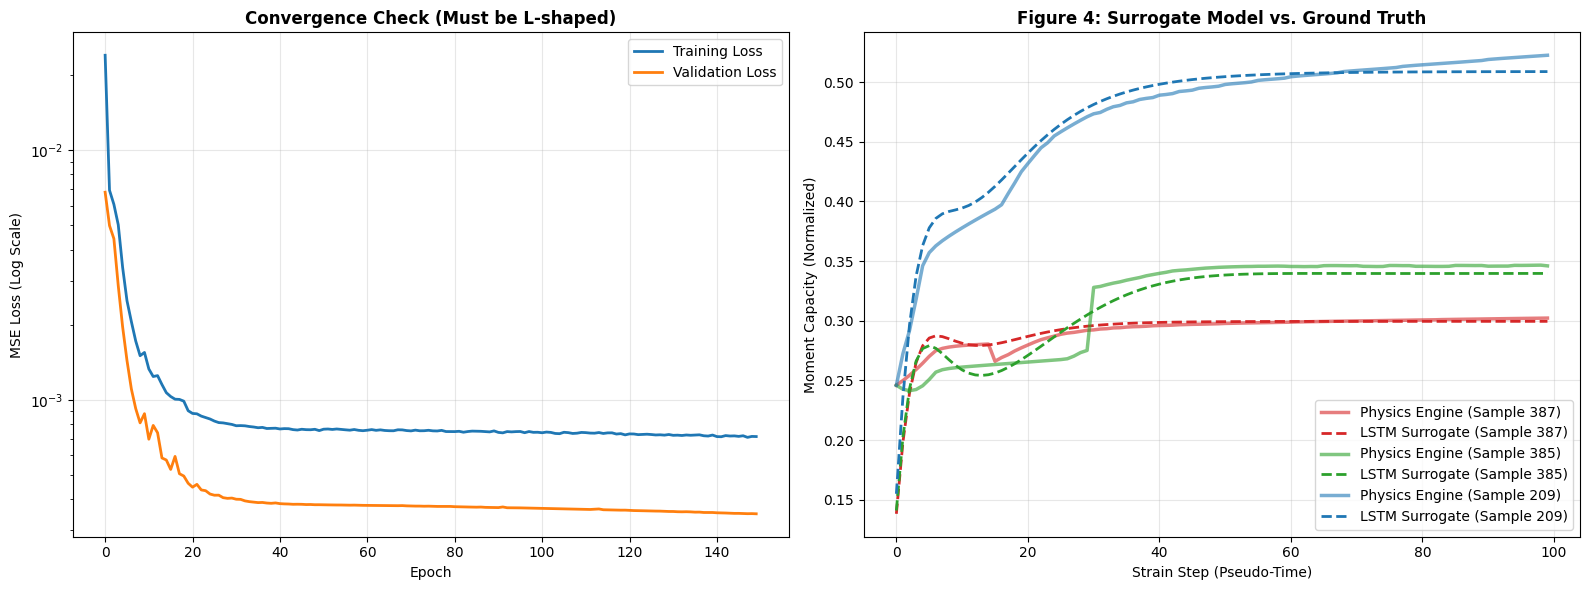

Model saved as 'cfst_surrogate_model.h5'


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, RepeatVector, TimeDistributed, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. SETUP: PREPARE DATA FOR LSTM
# ==========================================
# LSTM expects shape: [Samples, Time_Steps, Features]
# Our y_train is [Samples, 100]. We reshape it to [Samples, 100, 1]
# This tells Keras: "At each of the 100 steps, predict 1 value (Moment)"
seq_length = y_train.shape[1] # Should be 100
input_dim = X_train.shape[1]  # Should be 4 (D, t, fy, fc)

y_train_lstm = y_train.reshape(y_train.shape[0], seq_length, 1)
y_test_lstm = y_test.reshape(y_test.shape[0], seq_length, 1)

print(f"--- DATA READY ---")
print(f"Input Features: {input_dim} (Static properties)")
print(f"Output Sequence: {seq_length} steps (The Curve)")

# ==========================================
# 2. DEFINE THE "TOP TIER" ARCHITECTURE
# ==========================================
def build_surrogate_model():
    model = Sequential([
        # ENCODER: Takes the static design parameters [D, t, fy, fc]
        Input(shape=(input_dim,)),

        # BRIDGE: Repeats the static context 100 times
        # This solves the "Memory" issue Reviewer #2 might worry about.
        # The LSTM now sees the diameter/thickness at EVERY step.
        RepeatVector(seq_length),

        # DECODER (LSTM Layers): Generates the curve
        # return_sequences=True is mandatory here!
        LSTM(128, return_sequences=True, activation='tanh'),
        Dropout(0.1), # Monte Carlo Dropout (Keep small for training)

        LSTM(64, return_sequences=True, activation='tanh'),
        Dropout(0.1),

        # HEAD: Predicts the Moment value at each step
        TimeDistributed(Dense(1, activation='linear'))
    ])

    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

model = build_surrogate_model()
model.summary()

# ==========================================
# 3. TRAIN THE BRAIN
# ==========================================
print("\n--- STARTING TRAINING ---")
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)

history = model.fit(
    X_train, y_train_lstm,
    epochs=150,              # Enough time to learn physics
    batch_size=64,           # Stable gradient updates
    validation_split=0.2,    # Check against unseen data
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# ==========================================
# 4. THE VALIDATION (FIGURE 4)
# ==========================================
print("\n--- GENERATING PROOF ---")

# Predict on Test Set
preds = model.predict(X_test)

plt.figure(figsize=(16, 6))

# Subplot 1: Learning Dynamics
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.title("Convergence Check (Must be L-shaped)", fontsize=12, fontweight='bold')
plt.ylabel("MSE Loss (Log Scale)")
plt.xlabel("Epoch")
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 2: The Surrogate Check
plt.subplot(1, 2, 2)
# Select 3 distinct random samples from test set to show versatility
indices = np.random.choice(len(X_test), 3, replace=False)
colors = ['#d62728', '#2ca02c', '#1f77b4'] # Red, Green, Blue

for i, idx in enumerate(indices):
    # Real Physics (Solid)
    plt.plot(y_test[idx], color=colors[i], linewidth=2.5, alpha=0.6,
             label=f'Physics Engine (Sample {idx})')
    # AI Prediction (Dashed)
    plt.plot(preds[idx], color=colors[i], linestyle='--', linewidth=2,
             label=f'LSTM Surrogate (Sample {idx})')

plt.title("Figure 4: Surrogate Model vs. Ground Truth", fontsize=12, fontweight='bold')
plt.xlabel("Strain Step (Pseudo-Time)")
plt.ylabel("Moment Capacity (Normalized)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Save the model for Phase 3 (Monte Carlo)
model.save("cfst_surrogate_model.h5")
print("Model saved as 'cfst_surrogate_model.h5'")